In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
jobs = pd.read_csv("postings.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", jobs.shape)

display(jobs.head())

Dataset loaded successfully!
Dataset shape: (123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713400e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712860e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713280e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712900e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713450e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [3]:
# Check all column names
print(jobs.columns.tolist())

['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips']


In [11]:
# Check dataset information
jobs.info()
display(jobs[['title', 'description']].head())

<class 'pandas.DataFrame'>
Index: 123842 entries, 0 to 123848
Data columns (total 32 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123842 non-null  int64  
 1   company_name                122124 non-null  str    
 2   title                       123842 non-null  str    
 3   description                 123842 non-null  str    
 4   max_salary                  29792 non-null   float64
 5   pay_period                  36072 non-null   str    
 6   location                    123842 non-null  str    
 7   company_id                  122126 non-null  float64
 8   views                       122153 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29792 non-null   float64
 11  formatted_work_type         123842 non-null  str    
 12  applies                     23318 non-null   float64
 13  original_listed_time        12

,title,description
0,Marketing Coordinator,Job descriptionA leading real estate firm in N...
1,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ..."
2,Assitant Restaurant Manager,The National Exemplar is accepting application...
3,Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...
4,Service Technician,Looking for HVAC service tech with experience ...


In [10]:
# Check missing values in each column
print(jobs.isnull().sum())
# Count duplicate rows
print("Duplicate rows:", jobs.duplicated().sum())

job_id                             0
company_name                    1718
title                              0
description                        0
max_salary                     94050
pay_period                     87770
location                           0
company_id                      1716
views                           1689
med_salary                    117562
min_salary                     94050
formatted_work_type                0
applies                       100524
original_listed_time               0
remote_allowed                108599
job_posting_url                    0
application_url                36658
application_type                   0
expiry                             0
closed_time                   122771
formatted_experience_level     29402
skills_desc                   121403
listed_time                        0
posting_domain                 39961
sponsored                          0
work_type                          0
currency                       87770
c

In [9]:
# Remove rows where title or description is missing
jobs = jobs.dropna(subset=['title', 'description']).copy()

# Remove duplicate job postings
jobs = jobs.drop_duplicates().copy()

# Clean text columns
jobs['title'] = jobs['title'].astype(str).str.strip()
jobs['description'] = jobs['description'].astype(str).str.strip()

# Remove empty titles or descriptions
jobs = jobs[
    (jobs['title'] != '') &
    (jobs['description'] != '')
].copy()

print("Cleaned dataset shape:", jobs.shape)
display(jobs[['title', 'description']].head())
jobs['job_text'] = (
    jobs['title'] + ' ' +
    jobs['description']
)

print(jobs[['title', 'job_text']].head(3))

Cleaned dataset shape: (123842, 31)


,title,description
0,Marketing Coordinator,Job descriptionA leading real estate firm in N...
1,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ..."
2,Assitant Restaurant Manager,The National Exemplar is accepting application...
3,Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...
4,Service Technician,Looking for HVAC service tech with experience ...


                               title  \
0              Marketing Coordinator   
1  Mental Health Therapist/Counselor   
2        Assitant Restaurant Manager   

                                            job_text  
0  Marketing Coordinator Job descriptionA leading...  
1  Mental Health Therapist/Counselor At Aspen The...  
2  Assitant Restaurant Manager The National Exemp...  


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert job text into numerical vectors
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10000
)

tfidf_matrix = tfidf.fit_transform(jobs['job_text'])

print("TF-IDF model created successfully!")
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF model created successfully!
TF-IDF matrix shape: (123842, 10000)


In [25]:
from sklearn.metrics.pairwise import cosine_similarity

resume = """
Data Science student with skills in Python, SQL, Machine Learning,
Natural Language Processing, Pandas, NumPy and Scikit-learn.
Interested in Data Analyst, Data Scientist and Machine Learning roles.
"""

# Convert resume using the same TF-IDF model
resume_vector = tfidf.transform([resume])

# Compare resume with every job
similarity_scores = cosine_similarity(
    resume_vector,
    tfidf_matrix
).flatten()

print("Resume matching completed!")
print("Total jobs compared:", len(similarity_scores))

Resume matching completed!
Total jobs compared: 123842


In [26]:
jobs['similarity_score'] = similarity_scores

top_jobs = jobs.sort_values(
    by='similarity_score',
    ascending=False
).head(10)

display(
    top_jobs[['title', 'similarity_score']]
)

,title,similarity_score
116439,Lead Machine Learning Engineer,0.575521
118066,Senior Machine Learning Engineer,0.568002
108908,Applied Machine Learning Research Scientist,0.505633
42695,Principal Data Scientist,0.474495
119838,Senior Machine Learning Scientist,0.467554
18766,Senior Machine Learning Scientist,0.467554
23310,Lead Data Scientist,0.463221
59274,Machine Learning Engineer,0.461273
4767,Developer,0.458144
100524,Machine Learning Engineer - Remote,0.457891


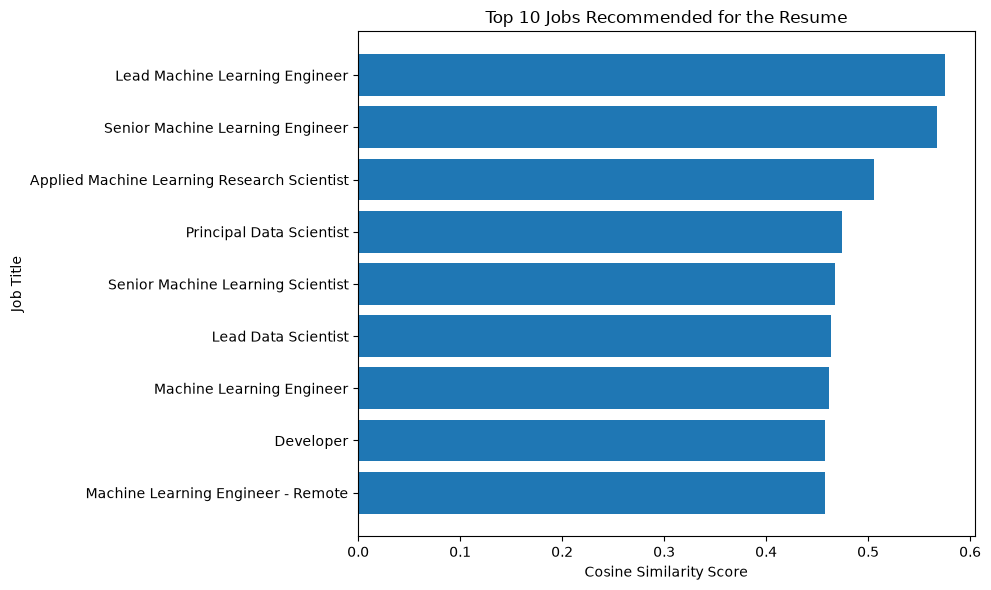

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_jobs['title'].astype(str).iloc[::-1],
    top_jobs['similarity_score'].iloc[::-1]
)

plt.xlabel("Cosine Similarity Score")
plt.ylabel("Job Title")
plt.title("Top 10 Jobs Recommended for the Resume")
plt.tight_layout()
plt.show()

In [37]:
def recommend_jobs(resume_text, top_n=10):
    resume_vector = tfidf.transform([resume_text])

    scores = cosine_similarity(
        resume_vector,
        tfidf_matrix
    ).flatten()

    results = jobs.copy()
    results['similarity_score'] = scores

    results = results.sort_values(
        by='similarity_score',
        ascending=False
    ).head(top_n)

    return results[
        ['title', 'similarity_score']
    ]

In [28]:
my_resume = """
MSc Data Science student.
Skills: Python, SQL, Pandas, NumPy, Machine Learning,
Natural Language Processing, Scikit-learn and data visualization.
Interested in Data Scientist, NLP Engineer and Data Analyst jobs.
"""

recommendations = recommend_jobs(my_resume, top_n=10)

display(recommendations)

,title,similarity_score
48185,Data Science intern -DIN51,0.554307
51466,Data Science intern -DIN52,0.554307
56793,Data Science intern -DIN53,0.554307
18239,Content Development | Data Science & NLP,0.540555
52026,Machine Learning Engineer- 10+year exp*,0.468173
24895,Data Scientist (Human Services experience),0.455473
38456,Data Scientist with GenAI,0.449433
116439,Lead Machine Learning Engineer,0.442524
69503,Data Scientist,0.442252
93632,Data Scientist,0.438915


In [29]:
print("Total jobs available:", len(jobs))
print("Jobs recommended:", len(recommendations))

print(
    "Highest similarity score:",
    round(recommendations['similarity_score'].max(), 4)
)

print(
    "Average similarity score:",
    round(recommendations['similarity_score'].mean(), 4)
)

Total jobs available: 123842
Jobs recommended: 10
Highest similarity score: 0.5543
Average similarity score: 0.49


In [30]:
%pip install pypdf

Note: you may need to restart the kernel to use updated packages.


In [32]:
sample_resume = """
MSc Data Science student with knowledge of Python, SQL,
Machine Learning, Natural Language Processing, Pandas,
NumPy, Scikit-learn, data analysis and data visualization.

Interested in Data Scientist, Data Analyst, NLP Engineer
and Machine Learning Engineer positions.
"""

print(sample_resume)
sample_recommendations = recommend_jobs(
    sample_resume,
    top_n=10
)

display(sample_recommendations)


MSc Data Science student with knowledge of Python, SQL,
Machine Learning, Natural Language Processing, Pandas,
NumPy, Scikit-learn, data analysis and data visualization.

Interested in Data Scientist, Data Analyst, NLP Engineer
and Machine Learning Engineer positions.



,title,similarity_score
116439,Lead Machine Learning Engineer,0.574463
48185,Data Science intern -DIN51,0.525996
51466,Data Science intern -DIN52,0.525996
56793,Data Science intern -DIN53,0.525996
52026,Machine Learning Engineer- 10+year exp*,0.512804
18239,Content Development | Data Science & NLP,0.505845
118066,Senior Machine Learning Engineer,0.487577
24895,Data Scientist (Human Services experience),0.484334
84952,Data Scientist,0.474547
13074,Junior Data Scientist - Python /Modeling,0.471040


In [33]:
print("Recommended jobs:", len(sample_recommendations))

print(
    "Best matching job:",
    sample_recommendations.iloc[0]["title"]
)

print(
    "Similarity score:",
    round(
        sample_recommendations.iloc[0]["similarity_score"],
        4
    )
)

Recommended jobs: 10
Best matching job: Lead Machine Learning Engineer
Similarity score: 0.5745


In [34]:
# Select useful columns available in the dataset
display_columns = [
    col for col in [
        'title',
        'company_name',
        'location',
        'similarity_score'
    ]
    if col in jobs.columns
]

# Get recommendations for the sample resume
resume_vector = tfidf.transform([sample_resume])

scores = cosine_similarity(
    resume_vector, tfidf_matrix
).flatten()

results = jobs.copy()
results['similarity_score'] = scores

top_recommendations = (
    results
    .sort_values('similarity_score', ascending=False)
    .drop_duplicates(subset=['title'])
    .head(10)
)

display(top_recommendations[display_columns])

,title,company_name,location,similarity_score
116439,Lead Machine Learning Engineer,Confidential Jobs,United States,0.574463
48185,Data Science intern -DIN51,Data Glacier,United States,0.525996
51466,Data Science intern -DIN52,Data Glacier,United States,0.525996
56793,Data Science intern -DIN53,Data Glacier,United States,0.525996
52026,Machine Learning Engineer- 10+year exp*,"Q1 Technologies, Inc.","Sunnyvale, CA",0.512804
18239,Content Development | Data Science & NLP,Way2Class,United States,0.505845
118066,Senior Machine Learning Engineer,Commit: AI Career Agents for Developers,United States,0.487577
24895,Data Scientist (Human Services experience),FUSTIS LLC,Washington DC-Baltimore Area,0.484334
84952,Data Scientist,NORC at the University of Chicago,"Chicago, IL",0.474547
13074,Junior Data Scientist - Python /Modeling,Expert Technical Solutions,"Atlanta, GA",0.471040


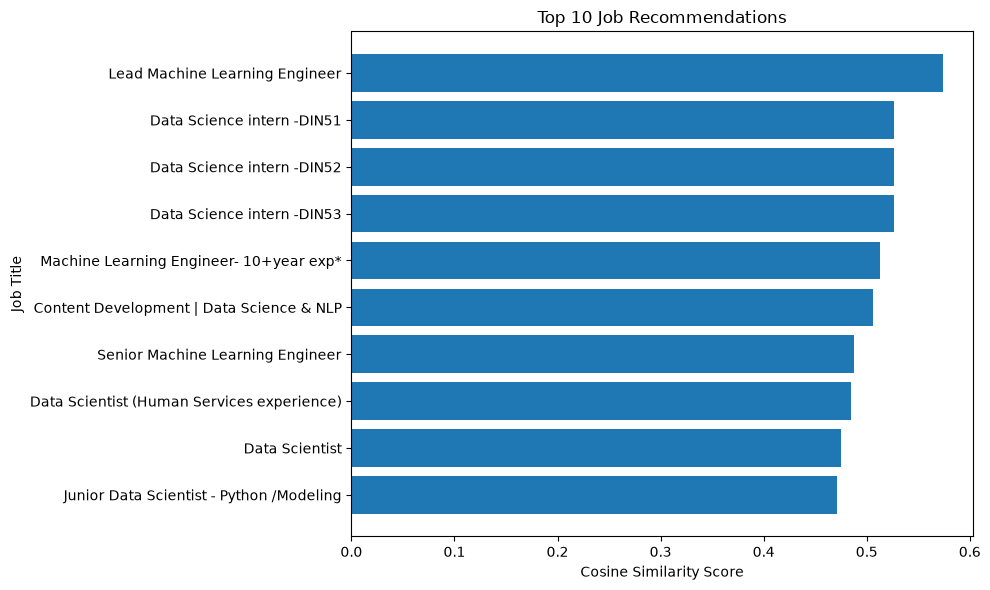

In [35]:
import matplotlib.pyplot as plt

plot_data = top_recommendations.iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data['title'].astype(str),
    plot_data['similarity_score']
)

plt.xlabel("Cosine Similarity Score")
plt.ylabel("Job Title")
plt.title("Top 10 Job Recommendations")
plt.tight_layout()
plt.show()

In [36]:
print("PROJECT EVALUATION SUMMARY")
print("-" * 35)
print("Total job postings:", len(jobs))
print("Unique job titles:", jobs['title'].nunique())
print("Jobs recommended:", len(top_recommendations))
print(
    "Highest similarity:",
    round(top_recommendations['similarity_score'].max(), 4)
)
print(
    "Average similarity:",
    round(top_recommendations['similarity_score'].mean(), 4)
)

PROJECT EVALUATION SUMMARY
-----------------------------------
Total job postings: 123842
Unique job titles: 72101
Jobs recommended: 10
Highest similarity: 0.5745
Average similarity: 0.5089
